## 1. Load dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q -o /content/drive/MyDrive/dataset.zip -d /content
!unzip -q -o /content/drive/MyDrive/raw_test.zip -d /content

!ls /content/dataset/train /content/raw_test

Mounted at /content/drive
/content/dataset/train:
A  B  C  D  E

/content/raw_test:
A  B  C  D  E


## 2. Build datasets

In [ ]:
import tensorflow as tf, numpy as np
from tensorflow import keras
from tensorflow.keras import layers

IMG, BS = (224, 224), 32

def load(path, shuffle=False):
    return keras.utils.image_dataset_from_directory(
        path, image_size=IMG, batch_size=BS, label_mode="int",
        shuffle=shuffle, seed=42)

train_ds = load("/content/dataset/train", shuffle=True)
val_ds   = load("/content/dataset/val")
test_ds  = load("/content/dataset/test")   # same conditions as training
dim_ds   = load("/content/raw_test")       # unseen: dim light

class_names = train_ds.class_names
print(class_names)
assert class_names == dim_ds.class_names == test_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Found 1383 files belonging to 5 classes.
Found 270 files belonging to 5 classes.
Found 287 files belonging to 5 classes.
Found 1756 files belonging to 5 classes.
['A', 'B', 'C', 'D', 'E']


## 3. Model

In [ ]:
aug = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.5, value_range=(0, 255)),
    layers.RandomContrast(0.4),
], name="augmentation")

base = keras.applications.MobileNetV2(
    input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG + (3,))
x = aug(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Train the new head (base frozen)

In [ ]:
h1 = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 25s 316ms/step - accuracy: 0.7202 - loss: 0.8200 - val_accuracy: 0.9148 - val_loss: 0.4383
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 309ms/step - accuracy: 0.9472 - loss: 0.2273 - val_accuracy: 0.9667 - val_loss: 0.2539
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 305ms/step - accuracy: 0.9725 - loss: 0.1370 - val_accuracy: 0.9667 - val_loss: 0.2006
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 293ms/step - accuracy: 0.9790 - loss: 0.1029 - val_accuracy: 0.9741 - val_loss: 0.1703
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 308ms/step - accuracy: 0.9812 - loss: 0.0797 - val_accuracy: 0.9704 - val_loss: 0.1569
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 13s 292ms/step - accuracy: 0.9848 - loss: 0.0672 - val_accuracy: 0.9519 - val_loss: 0.1656
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 306ms/step - accuracy: 0.9892 - loss: 0.0584 - val_accuracy: 0.9593 - val_loss: 0.1468
Epoch 8/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 305ms/step - accuracy: 0.9877 - loss: 0.0559 - val_accu

## 5. Fine-tune the top layers of MobileNetV2

In [ ]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=8)

Epoch 1/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 24s 324ms/step - accuracy: 0.9595 - loss: 0.1436 - val_accuracy: 0.9926 - val_loss: 0.0697
Epoch 2/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 317ms/step - accuracy: 0.9783 - loss: 0.0948 - val_accuracy: 0.9963 - val_loss: 0.0520
Epoch 3/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 300ms/step - accuracy: 0.9899 - loss: 0.0651 - val_accuracy: 0.9963 - val_loss: 0.0453
Epoch 4/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 313ms/step - accuracy: 0.9913 - loss: 0.0421 - val_accuracy: 1.0000 - val_loss: 0.0434
Epoch 5/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 300ms/step - accuracy: 0.9928 - loss: 0.0381 - val_accuracy: 0.9963 - val_loss: 0.0395
Epoch 6/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 300ms/step - accuracy: 0.9928 - loss: 0.0298 - val_accuracy: 1.0000 - val_loss: 0.0312
Epoch 7/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 316ms/step - accuracy: 0.9964 - loss: 0.0245 - val_accuracy: 1.0000 - val_loss: 0.0252
Epoch 8/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 14s 307ms/step - accuracy: 0.9949 - loss: 0.0214 - val_accuracy: 1.

## 6. Training curves (for the report)

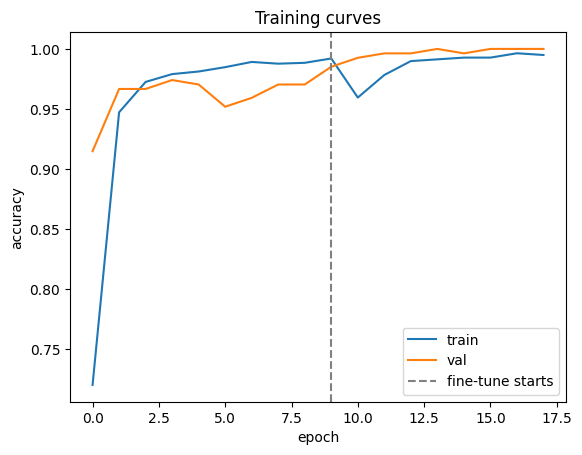

In [ ]:
import matplotlib.pyplot as plt
acc  = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
plt.plot(acc, label="train"); plt.plot(vacc, label="val")
plt.axvline(len(h1.history["accuracy"]) - 1, color="gray", ls="--", label="fine-tune starts")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("Training curves")
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Evaluate on both test sets

=== Test set (same conditions) ===  accuracy: 1.0000
              precision    recall  f1-score   support

           A      1.000     1.000     1.000        57
           B      1.000     1.000     1.000        55
           C      1.000     1.000     1.000        57
           D      1.000     1.000     1.000        64
           E      1.000     1.000     1.000        54

    accuracy                          1.000       287
   macro avg      1.000     1.000     1.000       287
weighted avg      1.000     1.000     1.000       287



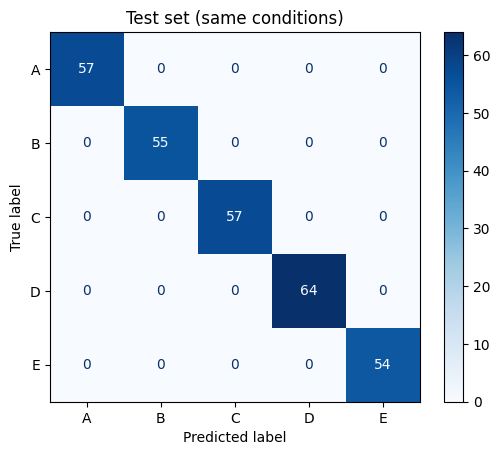

=== Unseen set (dim light + new background) ===  accuracy: 0.9989
              precision    recall  f1-score   support

           A      0.997     0.997     0.997       336
           B      1.000     0.997     0.999       359
           C      1.000     1.000     1.000       378
           D      1.000     1.000     1.000       366
           E      0.997     1.000     0.998       317

    accuracy                          0.999      1756
   macro avg      0.999     0.999     0.999      1756
weighted avg      0.999     0.999     0.999      1756



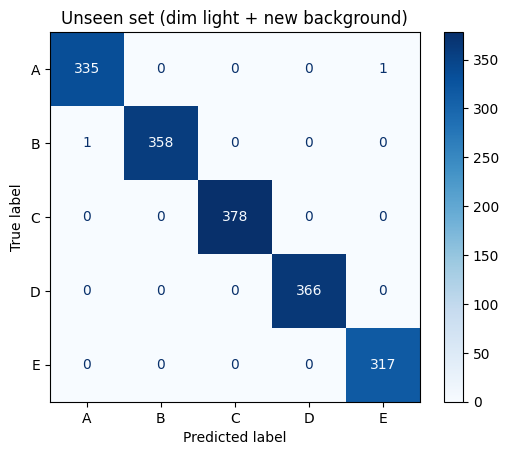

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

def evaluate(ds, title, fname):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = model.predict(ds, verbose=0).argmax(1)
    print(f"=== {title} ===  accuracy: {(y_true == y_pred).mean():.4f}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=class_names).plot(cmap="Blues")
    plt.title(title)
    plt.savefig(fname, dpi=150, bbox_inches="tight"); plt.show()
    return y_true, y_pred

evaluate(test_ds, "Test set (same conditions)", "cm_test.png")
y_true_dim, y_pred_dim = evaluate(dim_ds, "Unseen set (dim light + new background)", "cm_dim.png")

## 8. Failure examples on the unseen set (for the report)

2 misclassified of 1756


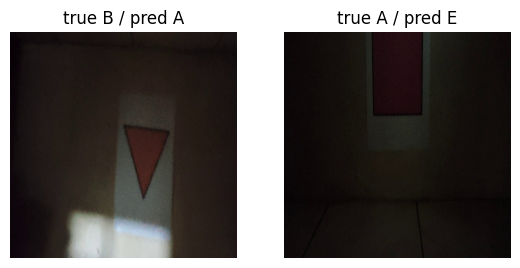

In [ ]:
images = np.concatenate([x.numpy() for x, _ in dim_ds]).astype("uint8")
wrong = np.where(y_true_dim != y_pred_dim)[0]
print(len(wrong), "misclassified of", len(y_true_dim))

if len(wrong):
    pick = np.random.RandomState(0).choice(wrong, min(9, len(wrong)), replace=False)
    plt.figure(figsize=(10, 10))
    for k, idx in enumerate(pick):
        plt.subplot(3, 3, k + 1)
        plt.imshow(images[idx]); plt.axis("off")
        plt.title(f"true {class_names[y_true_dim[idx]]} / pred {class_names[y_pred_dim[idx]]}")
    plt.savefig("failures.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Save the model

In [ ]:
model.save("marker_model.keras")
import json, shutil
json.dump(class_names, open("class_names.json", "w"))
for f in ["marker_model.keras", "class_names.json", "cm_test.png", "cm_dim.png",
          "training_curves.png", "failures.png"]:
    try: shutil.copy(f, "/content/drive/MyDrive/" + f)
    except FileNotFoundError: pass
print("saved to Drive")

saved to Drive
